In [1]:
import numpy as np
import pandas as pd

states = [
    (d, c, p)
    for d in range(3)
    for c in range(3)
    for p in range(3)
]

ACTIONS = [0, 1, 2]

HAPTIC_ACTIONS = {
    0: "Low",
    1: "Medium",
    2: "High"
}

print("Number of states:", len(states))
print("Actions:", HAPTIC_ACTIONS)

Number of states: 27
Actions: {0: 'Low', 1: 'Medium', 2: 'High'}


In [11]:
import numpy as np

HAPTIC_COST = {
    0: 0.00,
    1: 0.03,
    2: 0.08
}


def haptic_effect(
    action,
    difficulty,
    cognitive_effort,
    performance
):
    need = (
        0.4 * difficulty
        + 0.4 * cognitive_effort
        + 0.2 * (1 - performance)
    )

    if action == 0:
        return 0.00
    elif action == 1:
        return 0.15 * need
    elif action == 2:
        return 0.30 * need
    else:
        raise ValueError("Action must be 0, 1, or 2")


def probability_correct(
    ability,
    difficulty,
    cognitive_effort,
    alpha=4.0,
    beta=3.0,
    gamma=2.0
):
    score = (
        alpha * ability
        - beta * difficulty
        - gamma * cognitive_effort
    )

    return 1 / (1 + np.exp(-score))


def probability_correct_with_haptics(
    ability,
    difficulty,
    cognitive_effort,
    performance,
    action,
    alpha=4.0,
    beta=3.0,
    gamma=2.0
):
    base_score = (
        alpha * ability
        - beta * difficulty
        - gamma * cognitive_effort
    )

    effect = haptic_effect(
        action=action,
        difficulty=difficulty,
        cognitive_effort=cognitive_effort,
        performance=performance
    )

    final_score = base_score + effect

    return 1 / (1 + np.exp(-final_score))


def calculate_reward(
    correct,
    p_before,
    p_after,
    action
):
    success_reward = (
        1.0 if correct == 1 else -0.5
    )

    improvement = p_after - p_before

    haptic_cost = HAPTIC_COST[action]

    reward = (
        success_reward
        + 2.0 * improvement
        - haptic_cost
    )

    return reward


def environment_step(
    row,
    performance,
    action,
    rng
):
    ability = float(
        row["Learner_Ability"]
    )

    difficulty = float(
        row["Difficulty_D"]
    )

    cognitive_effort = float(
        row["Cognitive_Effort_C"]
    )

    p_before = probability_correct(
        ability=ability,
        difficulty=difficulty,
        cognitive_effort=cognitive_effort
    )

    p_after = probability_correct_with_haptics(
        ability=ability,
        difficulty=difficulty,
        cognitive_effort=cognitive_effort,
        performance=performance,
        action=action
    )

    p_after = np.clip(
        p_after,
        0.0,
        1.0
    )

    correct = rng.binomial(
        n=1,
        p=p_after
    )

    reward = calculate_reward(
        correct=correct,
        p_before=p_before,
        p_after=p_after,
        action=action
    )

    new_performance = (
        0.8 * performance
        + 0.2 * correct
    )

    new_performance = np.clip(
        new_performance,
        0.0,
        1.0
    )

    return (
        new_performance,
        reward,
        correct,
        p_before,
        p_after
    )

print("Phase 13 helper functions loaded into Phase 14")

Phase 13 helper functions loaded into Phase 14


In [2]:
LEARNING_RATE = 0.10
DISCOUNT_FACTOR = 0.95

EPSILON = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.995

N_EPISODES = 500
STEPS_PER_EPISODE = 50

print("Episodes:", N_EPISODES)
print("Steps per episode:", STEPS_PER_EPISODE)

Episodes: 500
Steps per episode: 50


In [3]:
Q = {
    state: np.zeros(3)
    for state in states
}

print("Example Q-values:")
print(Q[(0, 0, 0)])

Example Q-values:
[0. 0. 0.]


In [5]:
def choose_action(state, Q, epsilon, rng):

    if rng.random() < epsilon:
        return int(rng.choice(ACTIONS))

    q_values = Q[state]

    max_q = np.max(q_values)

    best_actions = np.flatnonzero(
        q_values == max_q
    )

    return int(
        rng.choice(best_actions)
    )

In [6]:
def performance_level(p):

    if p < 1/3:
        return 0

    elif p < 2/3:
        return 1

    else:
        return 2

In [7]:
simulation_df = pd.read_csv(
    "phase10_synthetic_learner_environment.csv"
)

print(simulation_df.shape)
print(simulation_df.columns.tolist())

(2127, 21)
['Excerpt', 'BT.Easiness', 'Predicted_BT_Easiness', 'Difficulty_D', 'Gaze_Score_Raw', 'Cognitive_Effort_C', 'D_level', 'C_level', 'D_label', 'C_label', 'Text_State', 'D_level_q', 'C_level_q', 'Learner_Profile', 'Learner_Ability', 'P_correct', 'Correct', 'Performance_P', 'P_level', 'P_label', 'RL_State']


In [8]:
required_columns = [
    "Difficulty_D",
    "Cognitive_Effort_C",
    "D_level",
    "C_level",
    "Learner_Profile",
    "Learner_Ability",
    "Performance_P"
]

for col in required_columns:
    print(col, "→", col in simulation_df.columns)

Difficulty_D → True
Cognitive_Effort_C → True
D_level → True
C_level → True
Learner_Profile → True
Learner_Ability → True
Performance_P → True


In [9]:
rng = np.random.default_rng(42)

episode_rewards = []
episode_accuracy = []

epsilon = EPSILON

In [12]:
print(environment_step)

<function environment_step at 0x1070b1f80>


In [13]:
# ==========================================
# PHASE 14 — Q-LEARNING IMPLEMENTATION
# ==========================================

import numpy as np
import pandas as pd

states = [
    (d, c, p)
    for d in range(3)
    for c in range(3)
    for p in range(3)
]

ACTIONS = [0, 1, 2]

HAPTIC_ACTIONS = {
    0: "Low",
    1: "Medium",
    2: "High"
}

print("Number of states:", len(states))
print("Actions:", HAPTIC_ACTIONS)

Number of states: 27
Actions: {0: 'Low', 1: 'Medium', 2: 'High'}


In [14]:
LEARNING_RATE = 0.10
DISCOUNT_FACTOR = 0.95

EPSILON = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.995

N_EPISODES = 500
STEPS_PER_EPISODE = 50

print("Learning rate:", LEARNING_RATE)
print("Discount factor:", DISCOUNT_FACTOR)
print("Initial epsilon:", EPSILON)
print("Episodes:", N_EPISODES)
print("Steps per episode:", STEPS_PER_EPISODE)

Learning rate: 0.1
Discount factor: 0.95
Initial epsilon: 1.0
Episodes: 500
Steps per episode: 50


In [15]:
Q = {
    state: np.zeros(len(ACTIONS))
    for state in states
}

print("Initial Q-values for state (0, 0, 0):")
print(Q[(0, 0, 0)])

Initial Q-values for state (0, 0, 0):
[0. 0. 0.]


In [16]:
def choose_action(
    state,
    Q,
    epsilon,
    rng
):
    # Explore
    if rng.random() < epsilon:
        return int(
            rng.choice(ACTIONS)
        )

    # Exploit
    q_values = Q[state]

    max_q = np.max(q_values)

    # Random tie-breaking
    best_actions = np.flatnonzero(
        q_values == max_q
    )

    return int(
        rng.choice(best_actions)
    )

In [17]:
def performance_level(performance):

    if performance < 1/3:
        return 0

    elif performance < 2/3:
        return 1

    else:
        return 2

In [18]:
print(performance_level(0.20))  # 0
print(performance_level(0.50))  # 1
print(performance_level(0.80))  # 2

0
1
2


In [19]:
simulation_df = pd.read_csv(
    "phase10_synthetic_learner_environment.csv"
)

print("Shape:", simulation_df.shape)
print(simulation_df.columns.tolist())

Shape: (2127, 21)
['Excerpt', 'BT.Easiness', 'Predicted_BT_Easiness', 'Difficulty_D', 'Gaze_Score_Raw', 'Cognitive_Effort_C', 'D_level', 'C_level', 'D_label', 'C_label', 'Text_State', 'D_level_q', 'C_level_q', 'Learner_Profile', 'Learner_Ability', 'P_correct', 'Correct', 'Performance_P', 'P_level', 'P_label', 'RL_State']


In [20]:
required_columns = [
    "Difficulty_D",
    "Cognitive_Effort_C",
    "D_level",
    "C_level",
    "Learner_Profile",
    "Learner_Ability",
    "Performance_P"
]

print("\nRequired columns:")

for col in required_columns:
    print(
        col,
        "→",
        col in simulation_df.columns
    )


Required columns:
Difficulty_D → True
Cognitive_Effort_C → True
D_level → True
C_level → True
Learner_Profile → True
Learner_Ability → True
Performance_P → True


In [21]:
print(
    simulation_df[
        required_columns
    ].isna().sum()
)

Difficulty_D          0
Cognitive_Effort_C    0
D_level               0
C_level               0
Learner_Profile       0
Learner_Ability       0
Performance_P         0
dtype: int64


In [22]:
rng = np.random.default_rng(42)

episode_rewards = []
episode_accuracy = []
episode_actions = []

epsilon = EPSILON

print("Training variables reset.")

Training variables reset.


In [23]:
for episode in range(N_EPISODES):

    total_reward = 0.0
    total_correct = 0

    action_counts = {
        0: 0,
        1: 0,
        2: 0
    }

    # Random starting row
    row_idx = rng.integers(
        0,
        len(simulation_df)
    )

    row = simulation_df.iloc[row_idx]

    performance = float(
        row["Performance_P"]
    )

    for step in range(STEPS_PER_EPISODE):

        # -----------------------------
        # Current state
        # -----------------------------

        state = (
            int(row["D_level"]),
            int(row["C_level"]),
            performance_level(performance)
        )

        # -----------------------------
        # Choose action
        # -----------------------------

        action = choose_action(
            state=state,
            Q=Q,
            epsilon=epsilon,
            rng=rng
        )

        action_counts[action] += 1

        # -----------------------------
        # Environment response
        # -----------------------------

        (
            new_performance,
            reward,
            correct,
            p_before,
            p_after
        ) = environment_step(
            row=row,
            performance=performance,
            action=action,
            rng=rng
        )

        # -----------------------------
        # Next passage for SAME learner
        # -----------------------------

        learner_rows = simulation_df[
            simulation_df["Learner_Profile"]
            == row["Learner_Profile"]
        ]

        next_row = learner_rows.iloc[
            rng.integers(
                0,
                len(learner_rows)
            )
        ]

        # -----------------------------
        # Next state
        # -----------------------------

        next_state = (
            int(next_row["D_level"]),
            int(next_row["C_level"]),
            performance_level(new_performance)
        )

        # -----------------------------
        # Q-learning update
        # -----------------------------

        current_q = Q[state][action]

        best_next_q = np.max(
            Q[next_state]
        )

        target = (
            reward
            + DISCOUNT_FACTOR
            * best_next_q
        )

        Q[state][action] = (
            current_q
            + LEARNING_RATE
            * (
                target
                - current_q
            )
        )

        # -----------------------------
        # Track episode statistics
        # -----------------------------

        total_reward += reward
        total_correct += correct

        # -----------------------------
        # Move environment forward
        # -----------------------------

        performance = new_performance
        row = next_row

    # =============================
    # End of episode
    # =============================

    episode_rewards.append(
        total_reward
    )

    episode_accuracy.append(
        total_correct
        / STEPS_PER_EPISODE
    )

    episode_actions.append(
        action_counts
    )

    # Reduce exploration
    epsilon = max(
        EPSILON_MIN,
        epsilon * EPSILON_DECAY
    )

In [24]:
print("Training completed!")
print("Number of episodes:", len(episode_rewards))

Training completed!
Number of episodes: 500


In [25]:
print(
    "Final epsilon:",
    round(epsilon, 4)
)

print(
    "Mean reward — first 50 episodes:",
    round(
        np.mean(episode_rewards[:50]),
        3
    )
)

print(
    "Mean reward — last 50 episodes:",
    round(
        np.mean(episode_rewards[-50:]),
        3
    )
)

print(
    "Mean accuracy — first 50 episodes:",
    round(
        np.mean(episode_accuracy[:50]),
        3
    )
)

print(
    "Mean accuracy — last 50 episodes:",
    round(
        np.mean(episode_accuracy[-50:]),
        3
    )
)

Final epsilon: 0.0816
Mean reward — first 50 episodes: 9.45
Mean reward — last 50 episodes: 11.674
Mean accuracy — first 50 episodes: 0.466
Mean accuracy — last 50 episodes: 0.494


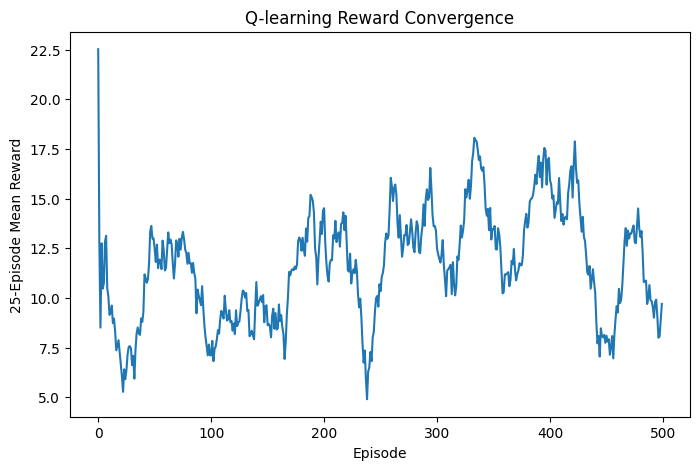

In [26]:
import matplotlib.pyplot as plt

reward_series = pd.Series(
    episode_rewards
)

reward_moving_average = (
    reward_series
    .rolling(
        window=25,
        min_periods=1
    )
    .mean()
)

plt.figure(figsize=(8, 5))

plt.plot(
    reward_moving_average
)

plt.xlabel("Episode")
plt.ylabel("25-Episode Mean Reward")
plt.title("Q-learning Reward Convergence")

plt.show()

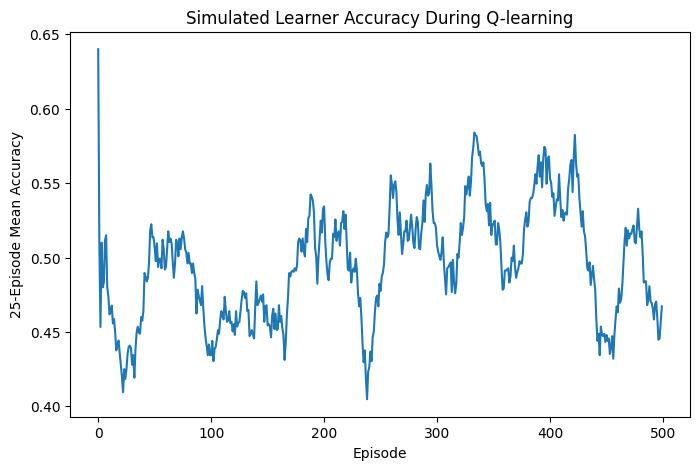

In [27]:
accuracy_series = pd.Series(
    episode_accuracy
)

accuracy_moving_average = (
    accuracy_series
    .rolling(
        window=25,
        min_periods=1
    )
    .mean()
)

plt.figure(figsize=(8, 5))

plt.plot(
    accuracy_moving_average
)

plt.xlabel("Episode")
plt.ylabel("25-Episode Mean Accuracy")
plt.title(
    "Simulated Learner Accuracy During Q-learning"
)

plt.show()

In [28]:
policy = {}

for state in states:

    best_action = int(
        np.argmax(
            Q[state]
        )
    )

    policy[state] = best_action

In [29]:
for state, action in sorted(
    policy.items()
):
    print(
        state,
        "→",
        HAPTIC_ACTIONS[action]
    )

(0, 0, 0) → Low
(0, 0, 1) → Medium
(0, 0, 2) → Medium
(0, 1, 0) → Low
(0, 1, 1) → Low
(0, 1, 2) → Low
(0, 2, 0) → High
(0, 2, 1) → Medium
(0, 2, 2) → Low
(1, 0, 0) → Medium
(1, 0, 1) → Medium
(1, 0, 2) → High
(1, 1, 0) → Medium
(1, 1, 1) → Medium
(1, 1, 2) → Low
(1, 2, 0) → Low
(1, 2, 1) → High
(1, 2, 2) → High
(2, 0, 0) → Low
(2, 0, 1) → Low
(2, 0, 2) → High
(2, 1, 0) → Medium
(2, 1, 1) → Medium
(2, 1, 2) → High
(2, 2, 0) → Medium
(2, 2, 1) → Medium
(2, 2, 2) → Medium


In [30]:
LEVEL_NAMES = {
    0: "Low",
    1: "Medium",
    2: "High"
}

policy_rows = []

for state in states:

    d, c, p = state

    action = policy[state]

    policy_rows.append(
        {
            "D_level": d,
            "D_label":
                LEVEL_NAMES[d],

            "C_level": c,
            "C_label":
                LEVEL_NAMES[c],

            "P_level": p,
            "P_label":
                LEVEL_NAMES[p],

            "Haptic_Action":
                action,

            "Haptic_Label":
                HAPTIC_ACTIONS[action]
        }
    )

policy_df = pd.DataFrame(
    policy_rows
)

print(policy_df)

    D_level D_label  C_level C_label  P_level P_label  Haptic_Action  \
0         0     Low        0     Low        0     Low              0   
1         0     Low        0     Low        1  Medium              1   
2         0     Low        0     Low        2    High              1   
3         0     Low        1  Medium        0     Low              0   
4         0     Low        1  Medium        1  Medium              0   
5         0     Low        1  Medium        2    High              0   
6         0     Low        2    High        0     Low              2   
7         0     Low        2    High        1  Medium              1   
8         0     Low        2    High        2    High              0   
9         1  Medium        0     Low        0     Low              1   
10        1  Medium        0     Low        1  Medium              1   
11        1  Medium        0     Low        2    High              2   
12        1  Medium        1  Medium        0     Low           

In [31]:


policy_df.to_csv(
    "phase14_qlearning_policy.csv",
    index=False
)

In [32]:
q_rows = []

for state in states:

    q_rows.append(
        {
            "D_level": state[0],
            "C_level": state[1],
            "P_level": state[2],

            "Q_Low":
                Q[state][0],

            "Q_Medium":
                Q[state][1],

            "Q_High":
                Q[state][2]
        }
    )

q_df = pd.DataFrame(
    q_rows
)

q_df.to_csv(
    "phase14_qtable.csv",
    index=False
)

print("Q-table saved.")

Q-table saved.


In [33]:
print(
    policy_df[
        "Haptic_Label"
    ].value_counts()
)

Haptic_Label
Medium    12
Low        9
High       6
Name: count, dtype: int64
